# Лабораторная работа №3. Регрессионный анализ
ФИО: __________________  
Группа: __________________  
Вариант: **13**, лист **var3** по согласованному циклическому правилу.

**Цель работы:** изучить простую и полиномиальную регрессию, сравнить несколько методов прогнозирования зарплаты.


## Загрузка файлов и библиотек


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# В Colab выберите два файла: regression (1).xlsx и salary.csv.
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

excel_file = next(Path('.').glob('regression*.xlsx'))
df = pd.read_excel(excel_file, sheet_name='var3')
salary = pd.read_csv('salary.csv')

# Одна функция для одинакового расчёта метрик всех моделей.
def metrics(y, prediction):
    mse = mean_squared_error(y, prediction)
    return {'MAE': mean_absolute_error(y, prediction),
            'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y, prediction)}


## Часть 1. Простая линейная регрессия
### 1. Описание данных и корреляции
`x1` и `x2` — числовые признаки, `y` — целевая переменная. Предметный смысл и единицы измерения в задании не указаны.


In [2]:
display(df.head(20))
display(df.describe())
print('Пропуски:', df.isna().sum().to_dict())
print('Дубликаты:', df.duplicated().sum())
display(df.corr(method='pearson'))


Пропуски: {'x1': 0, 'x2': 0, 'y': 0}
Дубликаты: 0


,x1,x2,y
0,1.696315,-0.548550,0.870770
1,-0.560186,1.176442,0.539647
2,1.493260,0.386962,1.049902
3,0.162986,-1.232673,-1.490034
4,0.344845,0.740232,1.737131
5,1.756825,1.342264,3.748636
6,-1.234110,0.665019,0.988839
7,0.853258,-1.163597,-0.842644
8,0.318094,-0.487262,-0.704140
9,1.779796,-1.369448,0.244140


,x1,x2,y
count,1000.000000,1000.000000,1000.000000
mean,0.000007,-0.000038,0.483917
std,1.155357,1.155261,1.670779
min,-1.998745,-1.996808,-3.498375
25%,-0.998825,-0.999651,-0.774310
50%,0.000264,0.001129,0.434032
75%,0.997258,0.998857,1.741084
max,1.997294,1.997547,5.060642


,x1,x2,y
x1,1.000000,0.010576,0.000333
x2,0.010576,1.000000,0.849765
y,0.000333,0.849765,1.000000


В наборе 1000 строк, пропусков и дубликатов нет. Корреляция `x1` и `y` близка к нулю (0,0003). Для `x2` и `y` она равна примерно 0,85: линейная связь сильная и положительная. Слабая корреляция сама по себе не исключает нелинейную связь.


### 2–9. Обучение двух моделей, прогнозы и графики
Для обеих моделей использую одно разбиение: 75% строк для обучения, 25% для валидации. Модели сравниваются на одинаковых наблюдениях.

MAE — средняя абсолютная ошибка, MSE — средняя квадратичная ошибка, RMSE — её корень в единицах целевой переменной. Чем меньше эти ошибки, тем лучше. R² показывает качество относительно прогноза среднего на оцениваемой выборке: максимум равен 1, значение может быть отрицательным.


x1: y = -0.03199 * x1 +0.45030
x2: y = 1.21685 * x2 +0.45990


,Факт,Прогноз,Прогноз − факт
2,1.049902,0.402531,-0.647371
3,-1.490034,0.445088,1.935122
10,2.025431,0.455829,-1.569602
23,-1.819759,0.433458,2.253217
25,4.607668,0.513399,-4.094269
29,0.501901,0.434531,-0.067369
30,3.285727,0.494037,-2.791690
31,-0.787755,0.413982,1.201737
33,2.874938,0.489942,-2.384997
39,0.572998,0.403627,-0.169370


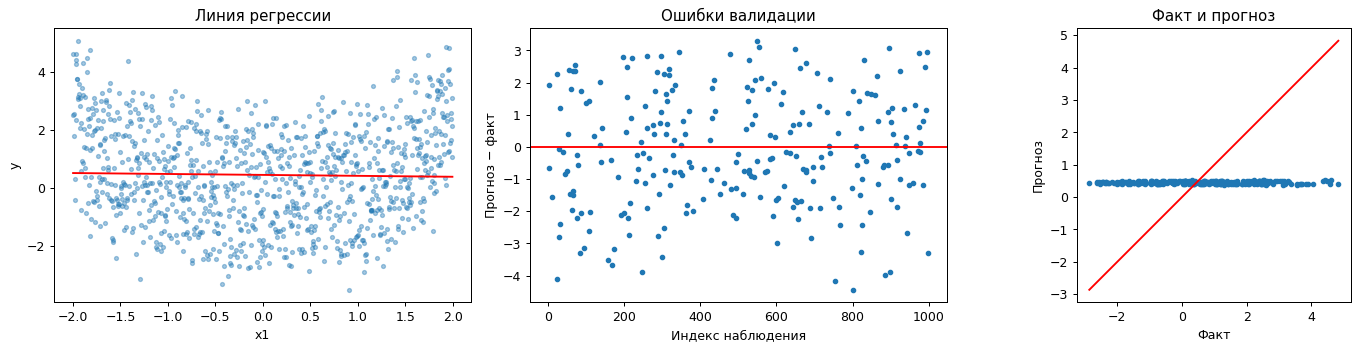

,Факт,Прогноз,Прогноз − факт
2,1.049902,0.930771,-0.119131
3,-1.490034,-1.040077,0.449957
10,2.025431,2.762180,0.736749
23,-1.819759,-0.992527,0.827232
25,4.607668,1.001304,-3.606364
29,0.501901,0.276615,-0.225286
30,3.285727,2.821461,-0.464265
31,-0.787755,-1.772563,-0.984808
33,2.874938,2.149737,-0.725202
39,0.572998,0.193730,-0.379268


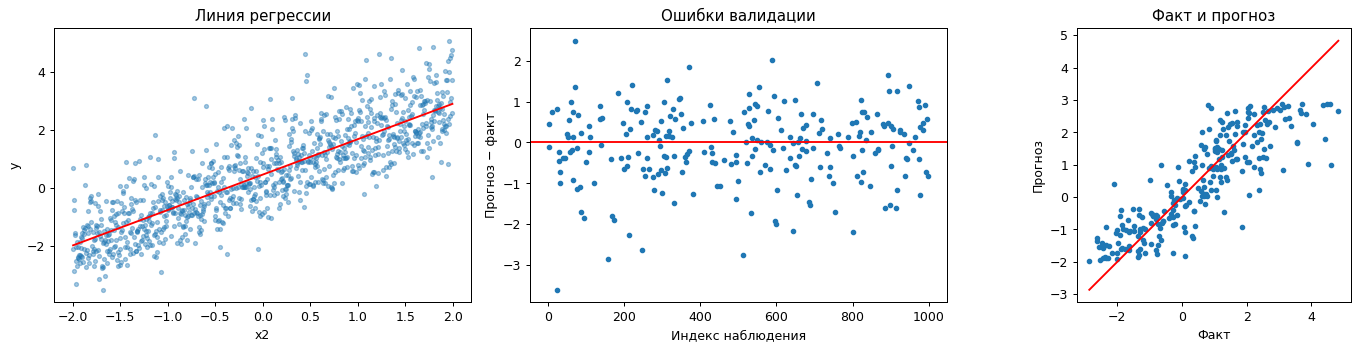

,Признак,MAE,MSE,RMSE,R2
0,x1,1.455234,3.075470,1.753702,-0.008890
1,x2,0.696717,0.823589,0.907518,0.729827


In [3]:
train_index, valid_index = train_test_split(df.index, test_size=0.25, random_state=42)
y_train_reg = df.loc[train_index, 'y']
y_valid_reg = df.loc[valid_index, 'y']
linear_results = []

for feature in ['x1', 'x2']:
    model = LinearRegression()
    model.fit(df.loc[train_index, [feature]], y_train_reg)
    prediction = model.predict(df.loc[valid_index, [feature]])
    linear_results.append({'Признак': feature, **metrics(y_valid_reg, prediction)})
    print(f'{feature}: y = {model.coef_[0]:.5f} * {feature} {model.intercept_:+.5f}')
    comparison = pd.DataFrame({'Факт': y_valid_reg, 'Прогноз': prediction})
    comparison['Прогноз − факт'] = comparison['Прогноз'] - comparison['Факт']
    with pd.option_context('display.max_rows', None):
        display(comparison.sort_index())

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    x_line = pd.DataFrame({feature: np.linspace(df[feature].min(), df[feature].max(), 200)})
    axes[0].scatter(df[feature], df['y'], s=10, alpha=0.4)
    axes[0].plot(x_line[feature], model.predict(x_line), color='red')
    axes[0].set(xlabel=feature, ylabel='y', title='Линия регрессии')
    errors = comparison.sort_index()['Прогноз − факт']
    axes[1].scatter(errors.index, errors, s=12)
    axes[1].axhline(0, color='red')
    axes[1].set(xlabel='Индекс наблюдения', ylabel='Прогноз − факт', title='Ошибки валидации')
    lo = min(y_valid_reg.min(), prediction.min())
    hi = max(y_valid_reg.max(), prediction.max())
    axes[2].scatter(y_valid_reg, prediction, s=12)
    axes[2].plot([lo, hi], [lo, hi], color='red')
    axes[2].set(xlabel='Факт', ylabel='Прогноз', title='Факт и прогноз')
    axes[2].set_aspect('equal', adjustable='box')
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(linear_results))


### 10. Вывод
Модель по `x2` точнее: MAE около 0,697 и R² около 0,730. Для `x1` MAE около 1,455, R² отрицательный. Поэтому из двух парных моделей выбираю модель по `x2`. На графике её прогнозы ближе к диагонали идеального совпадения.


## Часть 2. Полиномиальная регрессия
### 1–6. Сравнение степеней 2 и 3
Выбираю `x2`: в первой части он оказался полезнее для прогноза `y`. Проверю, улучшит ли добавление степеней этого признака качество по сравнению с прямой. Использую те же обучающие и валидационные строки. Степень сравниваю по MAE и R² на валидации.


Степень: 2
Степень: 3
Лучшая степень по MAE valid: 2


,Факт,Прогноз
521,-0.068690,-0.072733
737,0.373671,-0.447062
740,-1.625924,-1.506173
660,-0.280631,-0.620072
411,1.089776,0.847241
678,-2.158199,-1.701565
626,0.561486,-0.119271
513,1.837413,-0.918179
859,-1.183537,-1.418152
136,0.385483,1.268524


,Факт,Прогноз
521,-0.068690,-0.074326
737,0.373671,-0.449402
740,-1.625924,-1.505507
660,-0.280631,-0.622527
411,1.089776,0.848595
678,-2.158199,-1.699083
626,0.561486,-0.120987
513,1.837413,-0.920367
859,-1.183537,-1.418150
136,0.385483,1.270811


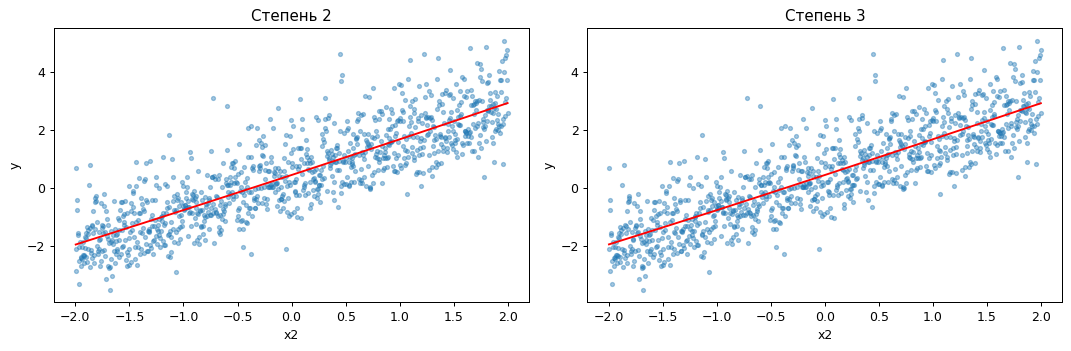

,Степень,R2 train,R2 valid,MAE train,MAE valid
0,2,0.718418,0.729167,0.685776,0.698166
1,3,0.718420,0.729191,0.685769,0.698246


In [4]:
poly_results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, degree in zip(axes, [2, 3]):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(df.loc[train_index, ['x2']])
    X_valid_poly = poly.transform(df.loc[valid_index, ['x2']])
    model_poly = LinearRegression()
    model_poly.fit(X_train_poly, y_train_reg)
    train_prediction = model_poly.predict(X_train_poly)
    valid_prediction = model_poly.predict(X_valid_poly)
    poly_results.append({'Степень': degree,
                         'R2 train': r2_score(y_train_reg, train_prediction),
                         'R2 valid': r2_score(y_valid_reg, valid_prediction),
                         'MAE train': mean_absolute_error(y_train_reg, train_prediction),
                         'MAE valid': mean_absolute_error(y_valid_reg, valid_prediction)})
    print('Степень:', degree)
    display(pd.DataFrame({'Факт': y_valid_reg, 'Прогноз': valid_prediction}).head(20))
    x_line = pd.DataFrame({'x2': np.linspace(df['x2'].min(), df['x2'].max(), 200)})
    ax.scatter(df['x2'], df['y'], s=10, alpha=0.4)
    ax.plot(x_line['x2'], model_poly.predict(poly.transform(x_line)), color='red')
    ax.set(xlabel='x2', ylabel='y', title=f'Степень {degree}')

plt.tight_layout()
plt.show()
poly_table = pd.DataFrame(poly_results)
display(poly_table)
print('Лучшая степень по MAE valid:', int(poly_table.loc[poly_table['MAE valid'].idxmin(), 'Степень']))


### 7. Вывод
Степень выбираю по качеству на валидации, а не только на обучении. Слишком низкая степень может не описать изгиб зависимости, слишком высокая — подстроиться под шум. Для этого листа полиномы дают результат, близкий к линейной модели. Если улучшение мало, разумнее оставить более простую модель. Численные результаты двух степеней приведены в таблице выше.

Среди двух полиномов меньше MAE у степени 2: MAE valid = 0.6982, R² valid = 0.7292. Существенного преимущества перед прямой нет.


## Часть 3. Прогноз зарплаты
### 1–2. Обзор данных и целевая переменная
Целевая переменная — `salary`, годовая зарплата. `income` означает доход до текущей работы и используется как признак.

Числовые признаки: возраст (`age`), предыдущий доход (`income`), опыт (`experience`), результат теста (`score_test`), рабочие часы (`hours_worked`), расстояние до работы (`distance_to_work`), сбережения (`savings`), долги (`debt`). Категориальные: образование (`education`), город (`city`), сфера работы (`job_type`), семейное положение (`marital_status`), автомобиль (`car`), удалённая работа (`remote_work`).


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1500 non-null   int64  
 1   income            1500 non-null   float64
 2   experience        1500 non-null   int64  
 3   score_test        1500 non-null   float64
 4   hours_worked      1500 non-null   int64  
 5   distance_to_work  1500 non-null   float64
 6   savings           1500 non-null   float64
 7   debt              1500 non-null   float64
 8   education         1500 non-null   object 
 9   city              1500 non-null   object 
 10  job_type          1500 non-null   object 
 11  marital_status    1500 non-null   object 
 12  car               1500 non-null   object 
 13  remote_work       1500 non-null   object 
 14  salary            1500 non-null   float64
dtypes: float64(6), int64(3), object(6)
memory usage: 175.9+ KB
Пропуски: {'age': 0, 'income':

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education,city,job_type,marital_status,car,remote_work,salary
0,56,70201.189680,25,87.559729,62,3.708690,25987.334048,2556.821627,PhD,Chicago,Finance,Single,Yes,Yes,106233.833479
1,69,51901.897395,39,70.808381,36,7.082793,22134.899021,725.180513,High School,Houston,Retail,Single,No,Yes,87205.291042
2,46,38605.409293,4,63.324996,77,5.129154,47106.068408,12659.359583,PhD,Los Angeles,Finance,Married,Yes,No,69369.283522
3,32,49949.736955,20,78.215505,33,19.315623,15868.328813,12369.776003,Bachelor,Los Angeles,IT,Married,Yes,No,76587.116955
4,60,48965.290095,13,74.429096,48,5.654904,15734.633332,4792.095213,Bachelor,Phoenix,IT,Married,No,No,71023.148842
5,25,11326.768555,3,73.022827,39,4.879219,11916.744037,6431.835876,Bachelor,Los Angeles,IT,Single,No,Yes,49665.609629
6,38,41579.497114,22,87.163120,49,11.706144,33558.588986,12271.330484,PhD,Chicago,Retail,Single,No,Yes,92451.866841
7,56,54713.055994,19,76.671392,38,9.224122,32785.043710,4876.906464,Bachelor,New York,Retail,Single,Yes,Yes,77558.755600
8,36,43636.766522,14,77.635691,72,1.134451,40287.795615,5796.929279,Master,Phoenix,Healthcare,Married,Yes,No,70917.649089
9,40,40306.859573,28,71.729474,58,7.096197,9083.212469,12941.384435,Master,New York,IT,Married,No,No,83196.215231


,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,salary
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,43.732000,50493.562171,19.479333,74.649867,49.046000,10.169171,19920.723043,7656.749308,98573.093521
std,15.071771,15354.495706,11.471529,9.904426,17.053654,10.003094,13635.530107,5481.390395,111786.756001
min,18.000000,-826.421240,0.000000,41.604998,20.000000,0.018137,408.482014,4.367130,28588.984258
25%,31.000000,40525.989722,10.000000,67.776127,34.000000,3.022163,9418.707911,3138.484219,69582.654903
50%,44.000000,50784.690569,19.000000,74.701567,49.000000,7.105165,17114.512522,6786.703775,80310.412797
75%,56.000000,61104.997961,29.000000,81.635633,63.000000,14.392065,27766.214001,11008.309571,91637.052601
max,69.000000,98819.709397,39.000000,107.261317,79.000000,82.597342,101890.570518,27276.705593,985625.114794


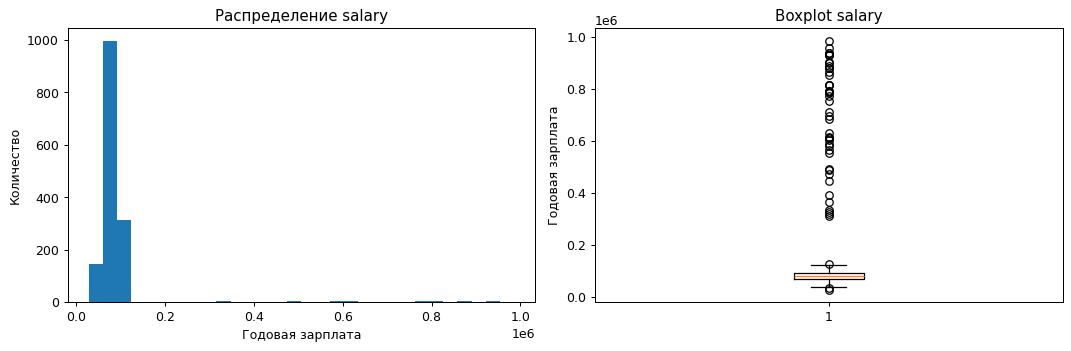

In [5]:
display(salary.head(20))
salary.info()
display(salary.describe())
print('Пропуски:', salary.isna().sum().to_dict())
print('Дубликаты:', salary.duplicated().sum())
for column in salary.select_dtypes(include='object'):
    print(column, ':', salary[column].unique())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(salary['salary'], bins=30)
axes[0].set(xlabel='Годовая зарплата', ylabel='Количество', title='Распределение salary')
axes[1].boxplot(salary['salary'])
axes[1].set(ylabel='Годовая зарплата', title='Boxplot salary')
plt.tight_layout()
plt.show()


### 3–6. Подготовка данных
В файле 1500 строк, пропусков и дубликатов нет. На гистограмме видны редкие очень большие зарплаты. В учебном эксперименте исключаю из **обучающей части** значения зарплаты за границами 1,5 IQR. Границы считаю только на train, а валидацию сохраняю полностью. Так проверяется и качество на редких больших зарплатах. Такое удаление — принятое правило подготовки, а не доказательство ошибки в исходных строках.

Разбиение выполняю до обработки, чтобы информация из валидации не влияла на обучение. Категории кодирую через `get_dummies(drop_first=True)`. Числовые признаки стандартизирую по train. Масштабирование особенно важно для kNN.


Строк до обработки: 1125
Исключено из train: 38
После обработки: 1087 Валидация: 375


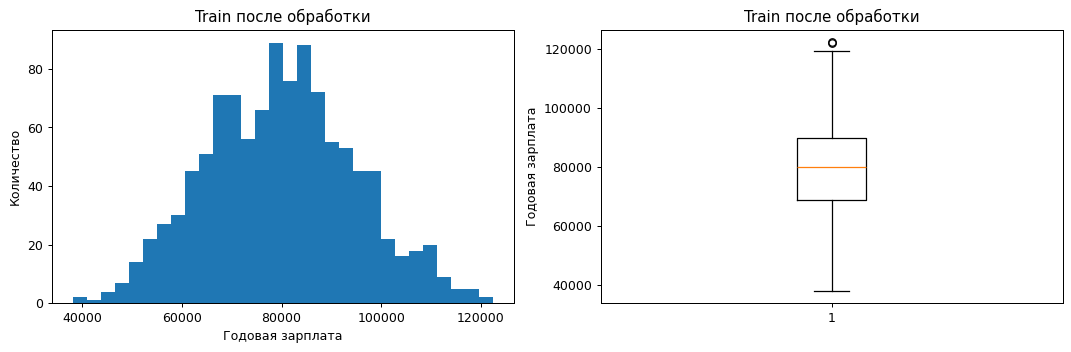

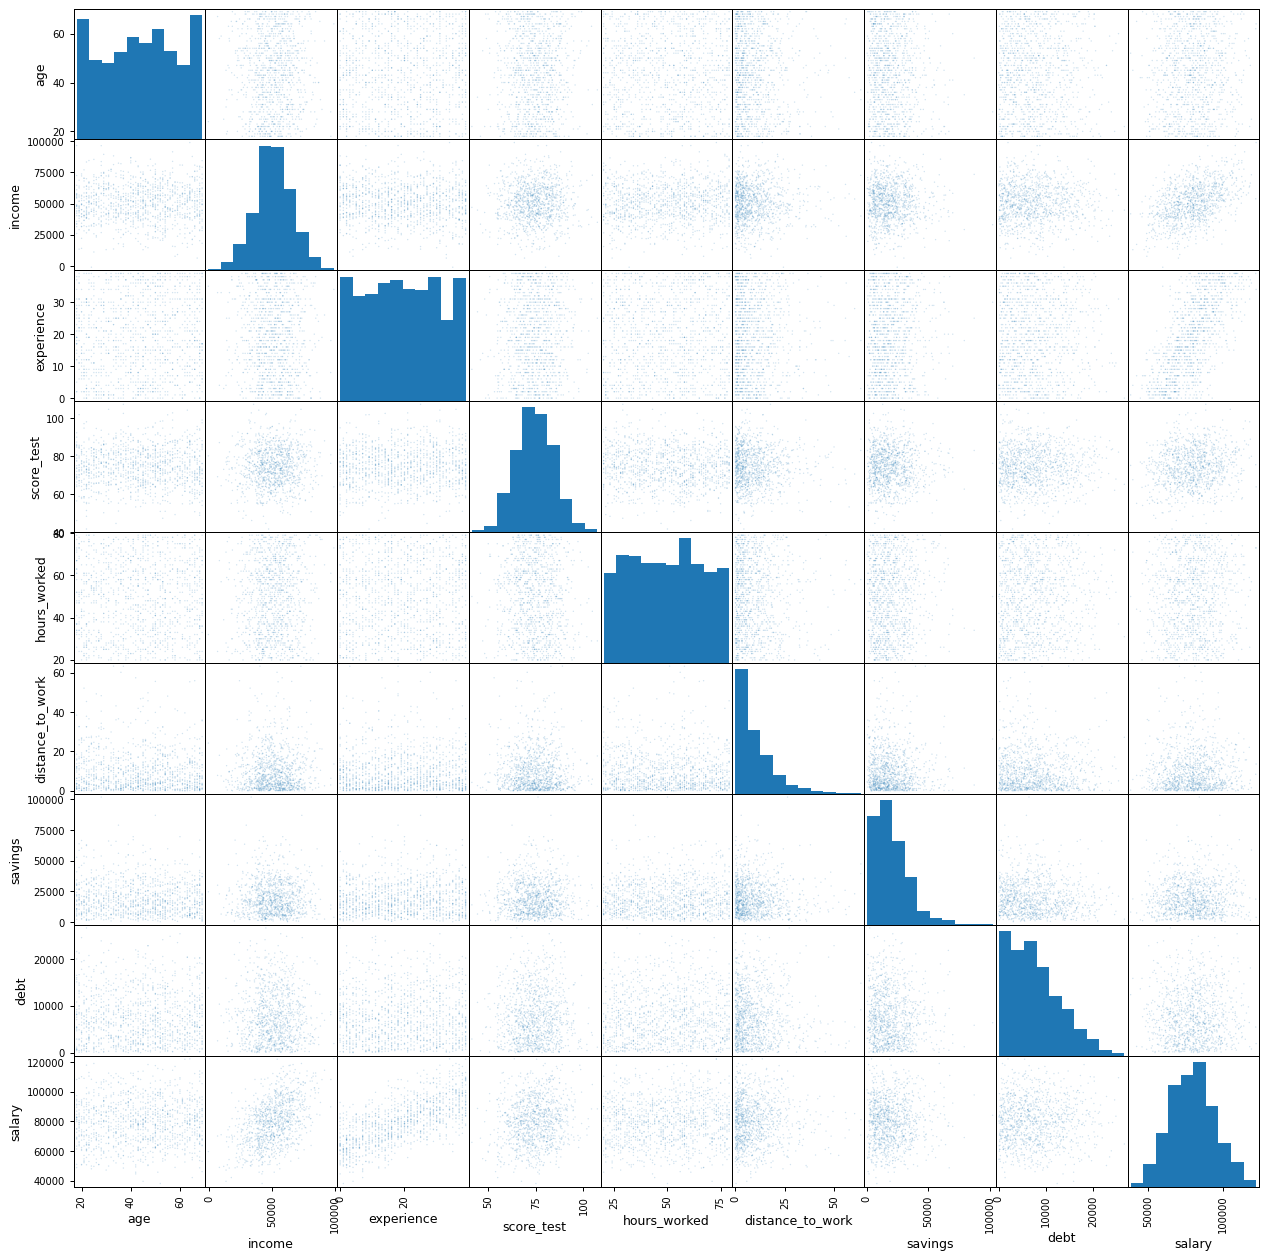

,age,income,experience,score_test,hours_worked,distance_to_work,savings,debt,education_High School,education_Master,education_PhD,city_Houston,city_Los Angeles,city_New York,city_Phoenix,job_type_Finance,job_type_Healthcare,job_type_IT,job_type_Retail,marital_status_Married,marital_status_Single,car_Yes,remote_work_Yes
807,-0.586539,-0.594067,0.490747,0.156947,1.390216,0.641256,2.657716,-0.542684,0,1,0,0,0,0,1,0,0,1,0,1,0,1,1
1229,-1.252407,-0.409248,1.266223,0.904218,-1.375007,-0.208539,-1.068544,-1.392672,0,0,0,0,0,1,0,0,0,0,1,0,1,1,1
1480,-1.185821,-1.767438,-1.577191,-0.884089,0.448864,0.194478,0.432639,-1.371984,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1
1436,0.412262,-0.079795,0.921567,0.293148,-1.669179,0.258861,-0.306021,0.059118,0,0,0,0,1,0,0,0,1,0,0,1,0,1,1
179,1.011543,-0.649429,-1.318698,0.018601,-0.963165,-0.929874,-0.412012,-1.042679,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1


In [6]:
X = salary.drop(columns='salary')
y = salary['salary']
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=42)

q1, q3 = y_train.quantile([0.25, 0.75])
iqr = q3 - q1
keep = y_train.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
print('Строк до обработки:', len(y_train))
print('Исключено из train:', (~keep).sum())
X_train = X_train.loc[keep].copy()
y_train = y_train.loc[keep].copy()
print('После обработки:', len(y_train), 'Валидация:', len(y_valid))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train, bins=30)
axes[0].set(xlabel='Годовая зарплата', ylabel='Количество', title='Train после обработки')
axes[1].boxplot(y_train)
axes[1].set(ylabel='Годовая зарплата', title='Train после обработки')
plt.tight_layout()
plt.show()

# Матрица рассеяния всех числовых признаков и цели на обучающих строках.
scatter_data = X_train.select_dtypes(include='number').assign(salary=y_train)
pd.plotting.scatter_matrix(scatter_data, figsize=(17, 17), diagonal='hist', alpha=0.2, s=5)
plt.show()

numeric_columns = X_train.select_dtypes(include='number').columns
X_train = pd.get_dummies(X_train, drop_first=True, dtype=int)
X_valid = pd.get_dummies(X_valid, drop_first=True, dtype=int)
X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0)

scaler = StandardScaler()
X_train[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_valid[numeric_columns] = scaler.transform(X_valid[numeric_columns])
display(X_train.head())


### 7–9, 12–13. Обучение и сравнение трёх методов
Использую линейную регрессию, kNN с пятью соседями и дерево с максимальной глубиной 5. Это заданные параметры для сравнения, подбор оптимальных параметров в обязательную часть не входит. Все три метода обучаю и проверяю на одинаковых строках.


In [7]:
models = {'Линейная регрессия': LinearRegression(),
          'kNN': KNeighborsRegressor(n_neighbors=5),
          'Дерево решений': DecisionTreeRegressor(max_depth=5, random_state=42)}
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_valid)
    predictions[name] = prediction
    results.append({'Модель': name, **metrics(y_valid, prediction)})

result_table = pd.DataFrame(results).set_index('Модель')
display(result_table)
comparison = pd.DataFrame({'Факт salary': y_valid})
for name, prediction in predictions.items():
    comparison[name] = prediction
with pd.option_context('display.max_rows', None):
    display(comparison.sort_index())


,MAE,MSE,RMSE,R2
Модель,,,,
Линейная регрессия,20703.268824,1.128191e+10,106216.314481,-0.014093
kNN,23942.058890,1.133392e+10,106460.862595,-0.018768
Дерево решений,23104.763441,1.125048e+10,106068.265249,-0.011268


,Факт salary,Линейная регрессия,kNN,Дерево решений
15,63876.307670,68530.749130,74704.157517,62855.193168
23,111198.257761,119802.123993,98102.892325,113509.502431
29,44219.056055,60578.770341,71389.417178,56255.723862
30,90837.188701,74617.500011,71133.471086,56255.723862
31,94294.390163,85034.685174,85936.401443,77076.289078
32,91766.966835,87527.296674,85216.138528,84612.640406
43,89125.427373,89619.716421,88540.859579,94043.959468
44,71288.910020,66637.726120,74416.727300,78459.376061
48,87096.671249,95693.409916,83024.025368,84612.640406
49,83843.268389,80531.867724,82788.081566,79902.491950


### 10. Коэффициенты линейной регрессии
Коэффициент числового признака показывает изменение прогноза при росте признака на одно стандартное отклонение, остальные признаки фиксированы. Коэффициент категории — разницу с базовой категорией. Эти два типа коэффициентов имеют разный смысл, поэтому их модули нельзя безусловно считать общим рейтингом важности. Связь с прогнозом не доказывает причинное влияние.

Среди числовых признаков наибольшие по модулю коэффициенты у experience, income, score_test. Их вклад сравнивается после стандартизации.


In [8]:
coefficients = pd.DataFrame({'Признак': X_train.columns,
                             'Коэффициент': models['Линейная регрессия'].coef_})
coefficients['Модуль'] = coefficients['Коэффициент'].abs()
display(coefficients.sort_values('Модуль', ascending=False))
print('Свободный член:', models['Линейная регрессия'].intercept_)
print('Базовые категории:')
for column in salary.select_dtypes(include='object'):
    print(column, ':', sorted(salary.loc[y_train.index, column].unique())[0])


Свободный член: 76610.2576209646
Базовые категории:
education : Bachelor
city : Chicago
job_type : Education
marital_status : Divorced
car : No
remote_work : No


,Признак,Коэффициент,Модуль
10,education_PhD,12082.157621,12082.157621
2,experience,10402.208185,10402.208185
1,income,7198.505970,7198.505970
8,education_High School,-6310.268003,6310.268003
9,education_Master,6065.694545,6065.694545
17,job_type_IT,3776.587054,3776.587054
15,job_type_Finance,2017.745403,2017.745403
13,city_New York,1628.161483,1628.161483
3,score_test,1425.035656,1425.035656
18,job_type_Retail,-1315.483000,1315.483000


### 11, 13. Визуализация факта и прогноза
Красная диагональ — идеальное совпадение. Чем ближе к ней точки, тем точнее прогноз.


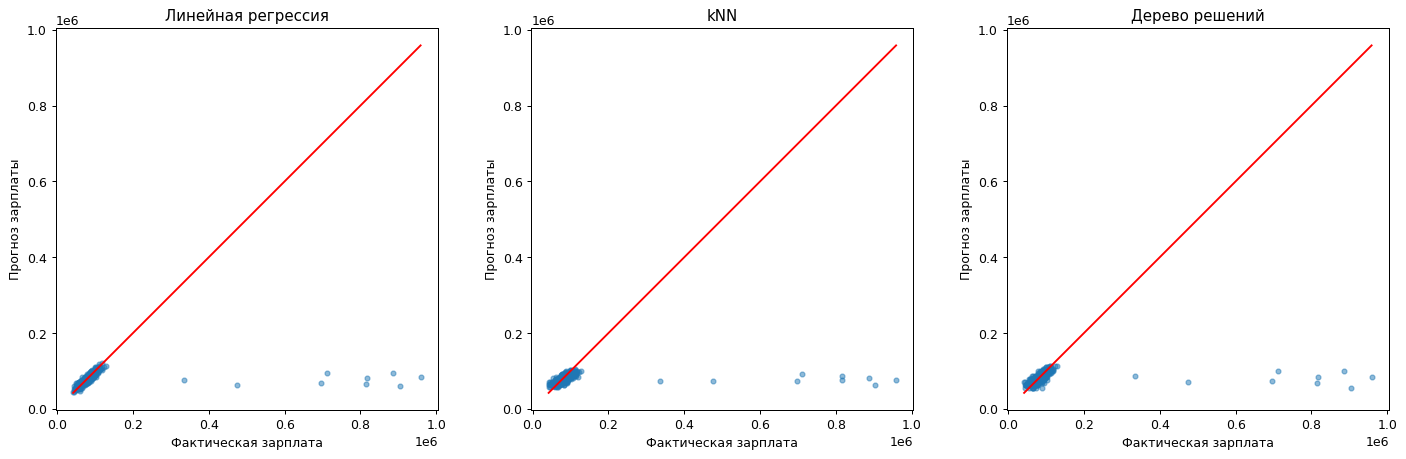

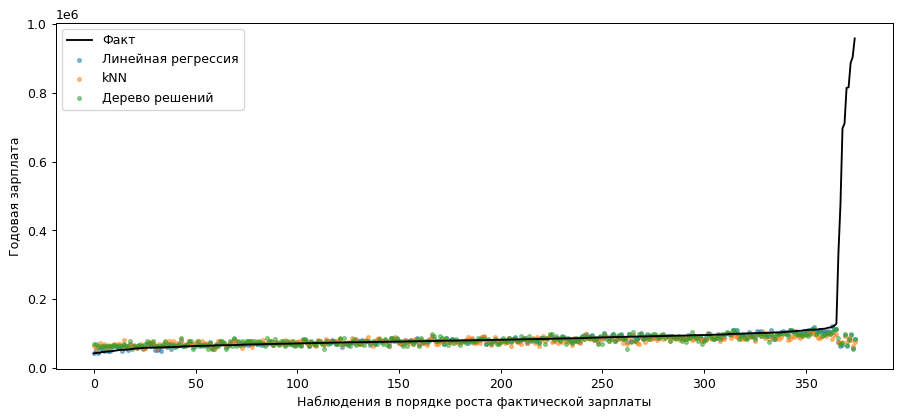

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, prediction) in zip(axes, predictions.items()):
    ax.scatter(y_valid, prediction, s=15, alpha=0.5)
    lo = min(y_valid.min(), prediction.min())
    hi = max(y_valid.max(), prediction.max())
    ax.plot([lo, hi], [lo, hi], color='red')
    ax.set(xlabel='Фактическая зарплата', ylabel='Прогноз зарплаты', title=name)
    ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

order = np.argsort(y_valid.to_numpy())
plt.figure(figsize=(12, 5))
plt.plot(y_valid.to_numpy()[order], color='black', label='Факт')
for name, prediction in predictions.items():
    plt.scatter(np.arange(len(order)), prediction[order], s=9, alpha=0.5, label=name)
plt.xlabel('Наблюдения в порядке роста фактической зарплаты')
plt.ylabel('Годовая зарплата')
plt.legend()
plt.show()


### 14. Вывод по задаче зарплаты
Сравниваю методы по общей валидационной выборке. При выборе по MAE предпочтительна модель с наименьшей средней абсолютной ошибкой. Если R² отрицательный, модель по квадрату ошибки хуже прогноза среднего на оцениваемой выборке. Даже небольшая MAE для обычных зарплат не гарантирует точного прогноза редких высоких значений.

По MAE выбираю метод «Линейная регрессия»: MAE = 20703.27, R² = -0.0141. У всех трёх методов R² отрицателен: большие зарплаты на графиках остаются недооценёнными. Поэтому этот выбор относится к средней абсолютной ошибке, а не к хорошему прогнозу всего диапазона зарплат.


In [10]:
best = result_table['MAE'].idxmin()
print('Наименьшая MAE:', best)
print('MAE:', round(result_table.loc[best, 'MAE'], 2))
print('R2:', round(result_table.loc[best, 'R2'], 4))
print('Наименьшая RMSE:', result_table['RMSE'].idxmin())
print('Три самых больших по модулю коэффициента среди числовых признаков:')
display(coefficients[coefficients['Признак'].isin(numeric_columns)].nlargest(3, 'Модуль'))


Наименьшая MAE: Линейная регрессия
MAE: 20703.27
R2: -0.0141
Наименьшая RMSE: Дерево решений
Три самых больших по модулю коэффициента среди числовых признаков:


,Признак,Коэффициент,Модуль
2,experience,10402.208185,10402.208185
1,income,7198.505970,7198.505970
3,score_test,1425.035656,1425.035656


## Общий вывод
В работе выполнены простая и полиномиальная регрессия для листа var3, а также прогноз годовой зарплаты. В первой части признак x2 оказался полезнее x1: R² линейной модели составил около 0,73. Во второй части сравнены полиномы второй и третьей степени, их результаты сопоставлены с прямой.

Для salary проверены пропуски и дубликаты, обработаны крайние зарплаты только в обучающей части, категории преобразованы в числовые столбцы, числовые признаки стандартизированы. Сравнены линейная регрессия, kNN и дерево решений по четырём метрикам. Лучший метод по MAE и его показатели приведены выше. Редкие высокие зарплаты затрудняют прогноз, поэтому качество необходимо оценивать вместе по таблице метрик и графикам.

В данных также встречаются неправдоподобные сочетания возраста и опыта. Без сведений об источнике они не исправлялись по предположению. Для практического применения потребовалась бы проверка качества исходных данных.
